TensorFlow: 2.21.0
Dataset: C:\Users\Vatsal\Desktop\Waste-Segregation-Model\DATASET
Class mapping: {0: 'Biodegradable', 1: 'Nonbiodegradable', 2: 'Recyclable'}


c:\Users\Vatsal\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Biodegradable: 14519 valid images
Nonbiodegradable: 13772 valid images
Recyclable: 13716 valid images

Training images: 33604
Validation images: 8403
Train distribution: {0: 11615, 1: 11017, 2: 10972}
Validation distribution: {0: 2904, 1: 2755, 2: 2744}

Pixel minimum: 0.0
Pixel maximum: 255.0
Batch shape: (32, 224, 224, 3)

========== STAGE 1 ==========
Epoch 1/8


c:\Users\Vatsal\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1051/1051 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.9585 - loss: 0.1181
Epoch 1: val_accuracy improved from None to 0.84874, saving model to C:\Users\Vatsal\Desktop\Waste-Segregation-Model\v4_best_head.keras

Epoch 1: finished saving model to C:\Users\Vatsal\Desktop\Waste-Segregation-Model\v4_best_head.keras
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 366s 341ms/step - accuracy: 0.9585 - loss: 0.1181 - val_accuracy: 0.8487 - val_loss: 0.4739 - learning_rate: 0.0010
Epoch 2/8
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.9667 - loss: 0.0949
Epoch 2: val_accuracy improved from 0.84874 to 0.87742, saving model to C:\Users\Vatsal\Desktop\Waste-Segregation-Model\v4_best_head.keras

Epoch 2: finished saving model to C:\Users\Vatsal\Desktop\Waste-Segregation-Model\v4_best_head.keras
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 378s 360ms/step - accuracy: 0.9667 - loss: 0.0949 - val_accuracy: 0.8774 - val_loss: 0.3970 - learning_rate: 0.0010
Epoch 3/8
1051/1051 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - ac

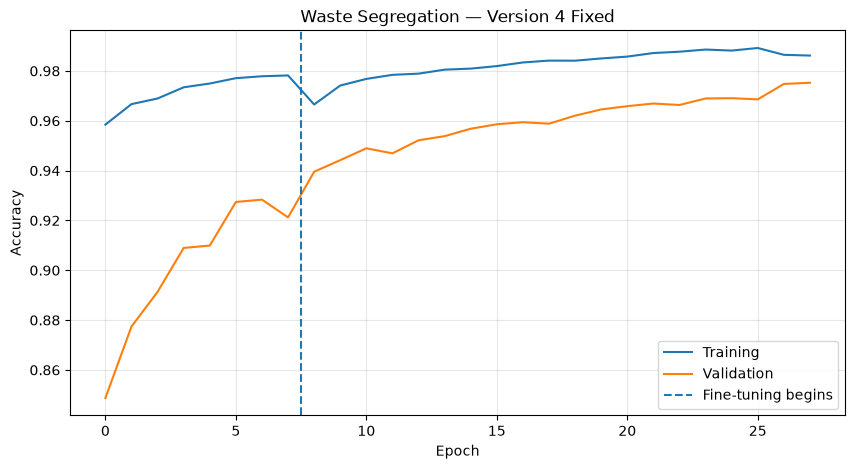

In [1]:

# ==========================================================
# WASTE SEGREGATION — VERSION 4 FIXED
# EfficientNetB0 + Two-Stage Transfer Learning
# Correct preprocessing + Stratified Validation
# ==========================================================

import os
from pathlib import Path
from collections import Counter

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from PIL import Image
import matplotlib.pyplot as plt

# -------------------- SETTINGS --------------------

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 20

CLASS_NAMES = [
    "Biodegradable",
    "Nonbiodegradable",
    "Recyclable"
]

PROJECT = Path(
    r"C:\Users\Vatsal\Desktop\Waste-Segregation-Model"
)
DATASET_PATH = PROJECT / "DATASET"

HEAD_FILE = PROJECT / "v4_best_head.keras"
FINE_FILE = PROJECT / "v4_best_finetuned.keras"
FINAL_FILE = PROJECT / "best_model_v4_fixed.keras"

keras.utils.set_random_seed(SEED)

if not DATASET_PATH.is_dir():
    raise FileNotFoundError(DATASET_PATH)

print("TensorFlow:", tf.__version__)
print("Dataset:", DATASET_PATH)
print("Class mapping:", dict(enumerate(CLASS_NAMES)))

# -------------------- CHECK IMAGES --------------------

# Accept both JPEG and PNG, regardless of extension.
# Do not delete or modify any original dataset files.

extensions = {".jpg", ".jpeg", ".png", ".bmp"}
files_by_class = []
invalid_files = []

for class_id, class_name in enumerate(CLASS_NAMES):
    folder = DATASET_PATH / class_name

    if not folder.is_dir():
        raise FileNotFoundError(folder)

    valid = []

    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue
        if path.suffix.lower() not in extensions:
            continue

        try:
            with Image.open(path) as im:
                im.load()
                im.convert("RGB")
            valid.append(str(path))

        except Exception as error:
            invalid_files.append((str(path), str(error)))

    files_by_class.append(valid)
    print(f"{class_name}: {len(valid)} valid images")

if invalid_files:
    print("\nUnreadable images skipped:", len(invalid_files))
    for path, error in invalid_files[:10]:
        print(path, error)

if any(len(files) < 10 for files in files_by_class):
    raise ValueError("Insufficient images in a class.")

# -------------------- STRATIFIED SPLIT --------------------

# Independently split each category into 80% train,
# 20% validation, ensuring each class appears in both.

rng = np.random.default_rng(SEED)

train_paths, train_labels = [], []
val_paths, val_labels = [], []

for class_id, files in enumerate(files_by_class):
    files = np.array(files)
    rng.shuffle(files)

    split = int(len(files) * 0.8)

    train_paths.extend(files[:split].tolist())
    train_labels.extend([class_id] * split)

    val_paths.extend(files[split:].tolist())
    val_labels.extend([class_id] * (len(files) - split))

print("\nTraining images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Train distribution:", dict(Counter(train_labels)))
print("Validation distribution:", dict(Counter(val_labels)))

# -------------------- IMAGE LOADER --------------------

# Pillow reads both PNG and JPEG.
# Output remains in 0-255 range for EfficientNetB0.

def read_image(path_value):
    path = os.fsdecode(
        path_value.item()
        if hasattr(path_value, "item")
        else path_value
    )

    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize(IMG_SIZE, Image.Resampling.BILINEAR)
        array = np.asarray(img, dtype=np.float32)

    return array

def load_tf_image(path, label):
    image = tf.numpy_function(
        read_image, [path], tf.float32
    )
    image.set_shape((224, 224, 3))
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (
            np.array(paths, dtype=str),
            np.array(labels, dtype=np.int32)
        )
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 4096),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_tf_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(
    train_paths, train_labels, training=True
)
val_ds = make_dataset(
    val_paths, val_labels, training=False
)

# -------------------- VERIFY PIXEL RANGE --------------------

sample_images, sample_labels = next(iter(train_ds))

print("\nPixel minimum:",
      float(tf.reduce_min(sample_images)))
print("Pixel maximum:",
      float(tf.reduce_max(sample_images)))
print("Batch shape:", sample_images.shape)

# -------------------- AUGMENTATION --------------------

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="waste_augmentation")

# -------------------- BUILD MODEL --------------------

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

# Correct: inputs are 0-255 already.
# No additional Rescaling(255) here.

x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    3, activation="softmax"
)(x)

model = keras.Model(
    inputs, outputs, name="Waste_V4_Fixed"
)

# -------------------- CALLBACKS --------------------

def callbacks(filename):
    return [
        keras.callbacks.ModelCheckpoint(
            str(filename),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

# ==========================================================
# STAGE 1 — TRAIN NEW CLASSIFIER
# ==========================================================

print("\n========== STAGE 1 ==========")

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks(HEAD_FILE)
)

stage1_best = max(history1.history["val_accuracy"])

# ==========================================================
# STAGE 2 — FINE-TUNE PRETRAINED BACKBONE
# ==========================================================

print("\n========== STAGE 2 ==========")

# Start fine-tuning from the best Stage 1 checkpoint.
model = keras.models.load_model(
    str(HEAD_FILE), compile=False
)

backbone = model.get_layer(base_model.name)
backbone.trainable = True

# Freeze earlier layers.
for layer in backbone.layers[:-50]:
    layer.trainable = False

# BatchNorm statistics should remain fixed.
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks(FINE_FILE)
)

stage2_best = max(history2.history["val_accuracy"])

# -------------------- SELECT BEST CHECKPOINT --------------------

if stage2_best > stage1_best:
    selected_file = FINE_FILE
    selected_stage = "Fine-tuned model"
else:
    selected_file = HEAD_FILE
    selected_stage = "Classification-head model"

final_model = keras.models.load_model(
    str(selected_file), compile=False
)

# Save the final best checkpoint under one filename.
final_model.save(str(FINAL_FILE))

# -------------------- FINAL EVALUATION --------------------

final_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

val_loss, val_accuracy = final_model.evaluate(
    val_ds, verbose=1
)

print("\n" + "=" * 55)
print("VERSION 4 FIXED — COMPLETED")
print("=" * 55)
print(f"Stage 1 best accuracy: {stage1_best*100:.2f}%")
print(f"Stage 2 best accuracy: {stage2_best*100:.2f}%")
print("Selected:", selected_stage)
print(f"Final validation accuracy: {val_accuracy*100:.2f}%")
print("Old V2 reported validation: 62.09%")
print(f"Numerical difference: {val_accuracy*100-62.09:+.2f} points")
print("Saved model:", FINAL_FILE)
print("=" * 55)

# -------------------- ACCURACY GRAPH --------------------

training_accuracy = (
    history1.history["accuracy"] +
    history2.history["accuracy"]
)

validation_accuracy = (
    history1.history["val_accuracy"] +
    history2.history["val_accuracy"]
)

plt.figure(figsize=(10, 5))
plt.plot(training_accuracy, label="Training")
plt.plot(validation_accuracy, label="Validation")
plt.axvline(
    len(history1.history["accuracy"]) - 0.5,
    linestyle="--",
    label="Fine-tuning begins"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Waste Segregation — Version 4 Fixed")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
